# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [1]:
# Twoje rozwiązanie

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

cechy = ["bill_length_mm", "bill_depth_mm"]
gatunki = ["Adelie", "Chinstrap", "Gentoo"]

df = sns.load_dataset("penguins").dropna(subset=cechy + ["species"])
X = df[cechy].values
y = df["species"].map({g: i for i, g in enumerate(gatunki)}).values

X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42)
print(len(X_train), len(X_val), len(X_test))

scaler = StandardScaler().fit(X_train)

X_tr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
X_va = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
X_te = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val, dtype=torch.long)
y_te = torch.tensor(y_test, dtype=torch.long)


204 69 69


In [2]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [3]:
# Twoje rozwiązanie

torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

with torch.no_grad():
    loss0 = loss_fn(model(X_tr), y_tr).item()
    p0 = torch.softmax(model(X_tr[:3]), dim=1)

print(f"loss przed uczeniem: {loss0:.3f}   (ln 3 = {np.log(3):.3f})")
print("prawdopodobieństwa dla 3 pingwinów:\n", p0.numpy().round(3))


loss przed uczeniem: 1.530   (ln 3 = 1.099)
prawdopodobieństwa dla 3 pingwinów:
 [[0.194 0.552 0.254]
 [0.33  0.384 0.286]
 [0.414 0.237 0.349]]


In [4]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

Loss to średnia z -ln(p), gdzie p to prawdopodobieństwo, które model dał prawdziwemu gatunkowi. Jeśli każdy gatunek dostaje 1/3, to dla każdego pingwina wychodzi -ln(1/3) = ln 3, więc średnia też wynosi ln 3. U mnie loss0 wyniósł 1.530, czyli jest wyższy niż ln 3 ~ 1.10, bo losowe wagi nie dają równych prawdopodobieństw i prawdziwy gatunek często dostaje mniej niż 1/3.

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

po 100 epokach: val loss = 0.149, val acc = 0.971


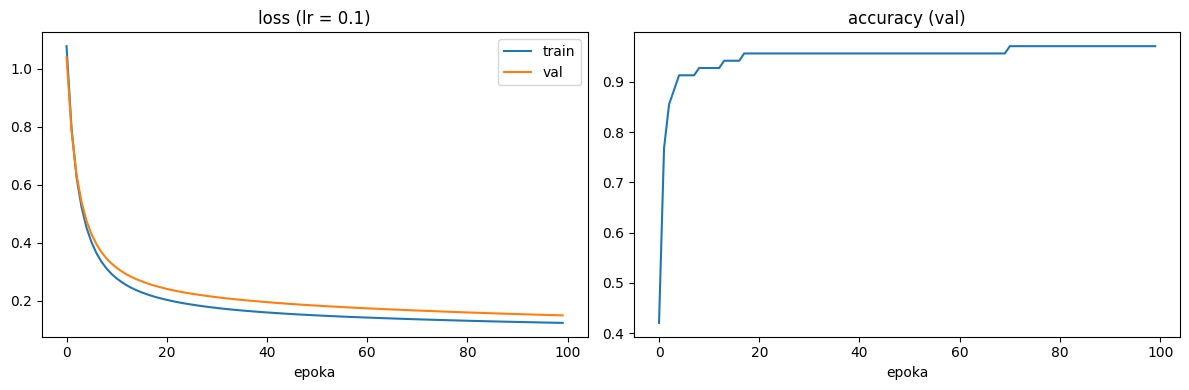

In [5]:
# Twoje rozwiązanie

def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    torch.manual_seed(seed)
    model = nn.Linear(2, 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            out_val = model(X_val)
            historia["val loss"].append(loss_fn(out_val, y_va).item())
            historia["val acc"].append((out_val.argmax(dim=1) == y_va).float().mean().item())
    return model, historia


model_01, hist_01 = train(0.1)
print(f"po 100 epokach: val loss = {hist_01['val loss'][-1]:.3f}, val acc = {hist_01['val acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["train loss"], label="train")
axes[0].plot(hist_01["val loss"], label="val")
axes[0].set_title("loss (lr = 0.1)"); axes[0].set_xlabel("epoka"); axes[0].legend()
axes[1].plot(hist_01["val acc"])
axes[1].set_title("accuracy (val)"); axes[1].set_xlabel("epoka")
plt.tight_layout(); plt.show()


In [6]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

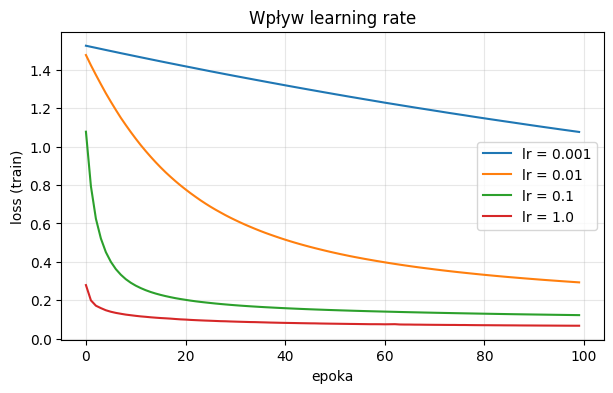

,val loss,val acc
lr,,
0.001,1.038,0.420
0.010,0.329,0.928
0.100,0.149,0.971
1.000,0.072,0.971


In [7]:
# Twoje rozwiązanie

modele = {}
wiersze = []
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.001, 0.01, 0.1, 1.0]:
    m, h = train(lr)
    modele[lr] = m
    ax.plot(h["train loss"], label=f"lr = {lr}")
    wiersze.append({"lr": lr, "val loss": h["val loss"][-1], "val acc": h["val acc"][-1]})
ax.set_xlabel("epoka"); ax.set_ylabel("loss (train)")
ax.set_title("Wpływ learning rate")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

wyniki_lr = pd.DataFrame(wiersze).set_index("lr")
wyniki_lr.round(3)


In [8]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

Dla learning rate = 0.001 loss prawie nie spada, bo kroki są za małe. Po 100 epokach val loss wynosi 1.038, a val accuracy 0.420. Wybieram learning rate = 1.0 na podstawie zbioru walidacyjnego, bo ma najmniejszy val loss (0.072), a val accuracy największą (0.971), taką samą jak learning rate = 0.1.

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

średnie cech bez standaryzacji: [43.9 17.1]
bez standaryzacji w trakcie uczenia: train loss od 0.232 do 124.437, val acc od 0.203 do 0.971
ze standaryzacją:  train loss = 0.123, val acc = 0.971
bez standaryzacji: train loss = 27.611, val acc = 0.797


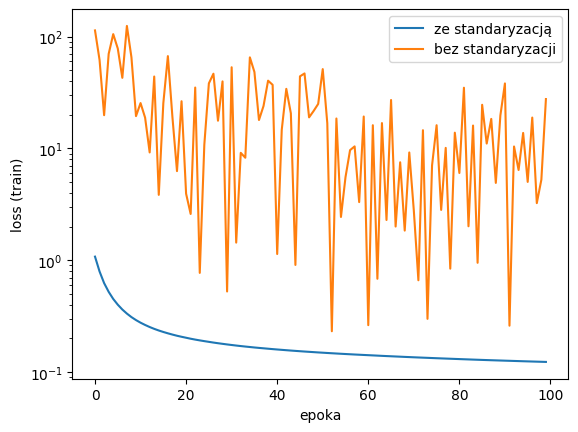

In [9]:
# Twoje rozwiązanie

X_tr_raw = torch.tensor(X_train, dtype=torch.float32)
X_va_raw = torch.tensor(X_val, dtype=torch.float32)

model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

print("średnie cech bez standaryzacji:", X_tr_raw.mean(dim=0).numpy().round(1))
print(f"bez standaryzacji w trakcie uczenia: train loss od {min(hist_raw['train loss']):.3f} do {max(hist_raw['train loss']):.3f}, "
      f"val acc od {min(hist_raw['val acc']):.3f} do {max(hist_raw['val acc']):.3f}")

print(f"ze standaryzacją:  train loss = {hist_01['train loss'][-1]:.3f}, val acc = {hist_01['val acc'][-1]:.3f}")
print(f"bez standaryzacji: train loss = {hist_raw['train loss'][-1]:.3f}, val acc = {hist_raw['val acc'][-1]:.3f}")

plt.plot(hist_01["train loss"], label="ze standaryzacją")
plt.plot(hist_raw["train loss"], label="bez standaryzacji")
plt.yscale("log"); plt.xlabel("epoka"); plt.ylabel("loss (train)")
plt.legend(); plt.show()


In [10]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

Bez standaryzacji cechy mają duże wartości (długość i wysokość dzioba pingwina wynoszą średnio 43.9 i 17.1), a po standaryzacji ich średnia wynosi 0. Gradient jest tym większy, im większe są wartości cech, więc przy learning rate = 0.1 kroki są za duże i model przeskakuje minimum, zamiast do niego zejść. Przez to train loss skacze w trakcie uczenia od 0.232 do 124.437 i po 100 epokach wynosi 27.611, a ze standaryzacją 0.123.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

wybrany lr: 1.0
PyTorch      accuracy (test): 0.957
scikit-learn accuracy (test): 0.928
   Adelie  Chinstrap  Gentoo  prawdziwy
0   0.969      0.031   0.000     Adelie
1   0.983      0.017   0.000     Adelie
2   0.000      0.005   0.995     Gentoo
3   0.001      0.110   0.889     Gentoo
4   0.087      0.909   0.004  Chinstrap


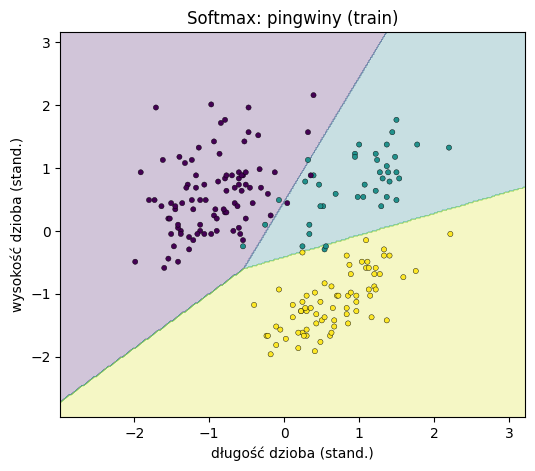

błędy na train: 8
przewidziany  Adelie  Chinstrap  Gentoo
prawdziwy                              
Adelie            89          2       0
Chinstrap          4         34       2
Gentoo             0          0      73


In [11]:
# Twoje rozwiązanie

from sklearn.linear_model import LogisticRegression

# 1. model wybrany na walidacji
najlepszy_lr = wyniki_lr["val loss"].idxmin()
model_koncowy = modele[najlepszy_lr]
print("wybrany lr:", najlepszy_lr)

with torch.no_grad():
    acc_test = (model_koncowy(X_te).argmax(dim=1) == y_te).float().mean().item()

# 2. scikit-learn
sk = LogisticRegression().fit(X_tr.numpy(), y_train)
acc_sk = sk.score(X_te.numpy(), y_test)
print(f"PyTorch      accuracy (test): {acc_test:.3f}")
print(f"scikit-learn accuracy (test): {acc_sk:.3f}")

# 3. prawdopodobieństwa dla 5 pingwinów testowych
with torch.no_grad():
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)
tabela = pd.DataFrame(p_test.numpy().round(3), columns=gatunki)
tabela["prawdziwy"] = [gatunki[i] for i in y_te[:5].tolist()]
print(tabela)


# 4. obszary decyzyjne (funkcja z wzoru)
def granica(model, X, y, tytul, softmax=False):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul); ax.set_xlabel("długość dzioba (stand.)"); ax.set_ylabel("wysokość dzioba (stand.)")
    plt.show()


granica(model_koncowy, X_tr.numpy(), y_train, "Softmax: pingwiny (train)", softmax=True)

with torch.no_grad():
    pred_tr = model_koncowy(X_tr).argmax(dim=1).numpy()
print("błędy na train:", (pred_tr != y_train).sum())
print(pd.crosstab(pd.Series([gatunki[i] for i in y_train], name="prawdziwy"),
                  pd.Series([gatunki[i] for i in pred_tr], name="przewidziany")))


In [12]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

*Twoja odpowiedź:*

1. Test accuracy mojego modelu wynosi 0.957, a LogisticRegression ze scikit-learn 0.928. To nie jest zaskakujące, bo to ten sam model z tym samym lossem, a różnica to tylko 2 pingwiny z 69 testowych. Wyniki trochę się różnią, bo scikit-learn używa innego algorytmu optymalizacji i regularyzacji.

2. Błędy leżą głównie na granicy między Adelie i Chinstrap, gdzie punkty tych dwóch gatunków na siebie nachodzą. Model liniowy nie zrobi tu niczego lepiej, bo jego granice to proste, a tych punktów nie da się rozdzielić żadną prostą.

3. Kroki pętli:
- forward: model dostaje batch pingwinów i dla każdego liczy trzy liczby (logity), po jednej dla każdego gatunku,
- loss: CrossEntropyLoss zamienia logity na prawdopodobieństwa i sprawdza, ile dostał prawdziwy gatunek, im mniej, tym większy loss,
- zero_grad: kasuje gradienty z poprzedniego kroku, bo PyTorch dodaje nowe do starych,
- backward: PyTorch liczy gradient, czyli jak zmieni się loss, gdy lekko zmienimy każdą wagę,
- step: optymalizator zmienia każdą wagę o mały krok (learning rate * gradient) tak, żeby loss zmalał.

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?

batch_size = 8: kroków w epoce = 26, train loss po 10 epokach = 0.164, po 100 epokach = 0.085, val acc = 0.957
batch_size = 32: kroków w epoce = 7, train loss po 10 epokach = 0.292, po 100 epokach = 0.123, val acc = 0.971
batch_size = 204: kroków w epoce = 1, train loss po 10 epokach = 0.932, po 100 epokach = 0.241, val acc = 0.942


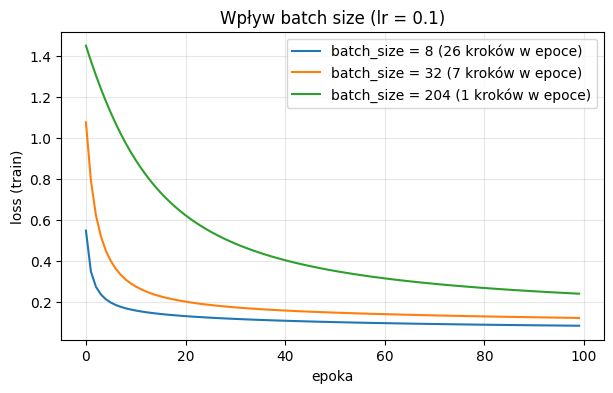

In [13]:
# Twoje rozwiązanie

# 7.1 batch size
fig, ax = plt.subplots(figsize=(7, 4))
for bs in [8, 32, 204]:
    _, h = train(0.1, batch_size=bs)
    kroki = int(np.ceil(len(X_tr) / bs))
    ax.plot(h["train loss"], label=f"batch_size = {bs} ({kroki} kroków w epoce)")
    print(f"batch_size = {bs}: kroków w epoce = {kroki}, train loss po 10 epokach = {h['train loss'][9]:.3f}, "
          f"po 100 epokach = {h['train loss'][-1]:.3f}, val acc = {h['val acc'][-1]:.3f}")
ax.set_xlabel("epoka"); ax.set_ylabel("loss (train)")
ax.set_title("Wpływ batch size (lr = 0.1)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()


*Twoja odpowiedź:* Dla batch_size = 8, 32 i 204 liczba kroków w epoce wynosi odpowiednio 26, 7 i 1, więc najwięcej kroków robi batch_size = 8. Train loss po 10 epokach wynosi odpowiednio 0.164, 0.292 i 0.932, więc w przeliczeniu na epoki najszybciej uczy się batch_size = 8. Im mniejszy batch, tym więcej razy w epoce model poprawia wagi.

SGD lr = 0.1: train loss po 10 epokach = 0.292, po 100 epokach = 0.123, val loss = 0.149, val acc = 0.971
Adam lr = 0.01: train loss po 10 epokach = 0.580, po 100 epokach = 0.128, val loss = 0.153, val acc = 0.971


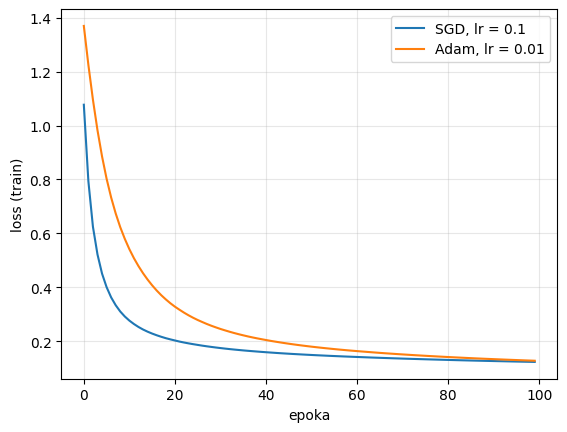

In [14]:
# Twoje rozwiązanie

# 7.2 Adam - ta sama pętla co w train, tylko z wyborem optymalizatora i liczby cech
def train_opt(lr, opt=optim.SGD, X=X_tr, X_val=X_va, epochs=100, batch_size=32, seed=0):
    torch.manual_seed(seed)
    model = nn.Linear(X.shape[1], 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = opt(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            out_val = model(X_val)
            historia["val loss"].append(loss_fn(out_val, y_va).item())
            historia["val acc"].append((out_val.argmax(dim=1) == y_va).float().mean().item())
    return model, historia


_, hist_adam = train_opt(0.01, opt=optim.Adam)

for nazwa, h in [("SGD lr = 0.1", hist_01), ("Adam lr = 0.01", hist_adam)]:
    print(f"{nazwa}: train loss po 10 epokach = {h['train loss'][9]:.3f}, po 100 epokach = {h['train loss'][-1]:.3f}, "
          f"val loss = {h['val loss'][-1]:.3f}, val acc = {h['val acc'][-1]:.3f}")

plt.plot(hist_01["train loss"], label="SGD, lr = 0.1")
plt.plot(hist_adam["train loss"], label="Adam, lr = 0.01")
plt.xlabel("epoka"); plt.ylabel("loss (train)")
plt.legend(); plt.grid(alpha=0.3); plt.show()


*Twoja odpowiedź:* Po 100 epokach Adam i SGD dają prawie to samo. Train loss wynosi 0.128 dla Adama i 0.123 dla SGD, a val accuracy w obu przypadkach 0.971. Na początku SGD uczy się szybciej, bo po 10 epokach train loss wynosi dla niego 0.292, a dla Adama 0.580. Adam ma tu jednak 10 razy mniejszy learning rate (0.01 zamiast 0.1).

In [15]:
# Twoje rozwiązanie

# 7.3 cztery cechy
cechy4 = cechy + ["flipper_length_mm", "body_mass_g"]
X4 = df[cechy4].values

X4_rest, X4_test, _, _ = train_test_split(X4, y, test_size=0.2, stratify=y, random_state=42)
X4_train, X4_val, _, _ = train_test_split(X4_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42)

scaler4 = StandardScaler().fit(X4_train)
X4_tr = torch.tensor(scaler4.transform(X4_train), dtype=torch.float32)
X4_va = torch.tensor(scaler4.transform(X4_val), dtype=torch.float32)
X4_te = torch.tensor(scaler4.transform(X4_test), dtype=torch.float32)

model_4, hist_4 = train_opt(0.1, X=X4_tr, X_val=X4_va)
print(model_4)

with torch.no_grad():
    acc_test_4 = (model_4(X4_te).argmax(dim=1) == y_te).float().mean().item()
    acc_test_2 = (model_01(X_te).argmax(dim=1) == y_te).float().mean().item()

print(f"2 cechy (lr = 0.1): val acc = {hist_01['val acc'][-1]:.3f}, test acc = {acc_test_2:.3f}")
print(f"4 cechy (lr = 0.1): val acc = {hist_4['val acc'][-1]:.3f}, test acc = {acc_test_4:.3f}")


Linear(in_features=4, out_features=3, bias=True)
2 cechy (lr = 0.1): val acc = 0.971, test acc = 0.928
4 cechy (lr = 0.1): val acc = 0.971, test acc = 1.000


*Twoja odpowiedź:* Oba modele są uczone z learning rate = 0.1. Val accuracy się nie zmieniła (0.971 dla 2 i dla 4 cech), ale test accuracy wzrosła z 0.928 do 1.000, czyli o trochę ponad 7 p.p. Model z 4 cechami nie pomylił się na żadnym pingwinie testowym, a model z 2 cechami pomylił się na 5.